# ATR-FTIR *Pinus pinaster* / *Fusarium circinatum*: hyperparameter tuning of the best classifiers

Selects and tunes the best classifiers for separating infected from control plants, trained on the pooled asymptomatic window (T1–T5).

Candidates are chosen globally: the three (spectrum type, region, R value, model) combinations with the highest pooled T1–T5 CV MCC across all six combinations of spectrum type (`Raw`, `2nd Derivative`) and region (`Combined`, `Fingerprint`, `Stretching`). It does not matter whether they come from raw or second-derivative data, or from the same region.

The notebook loads the feature-selected datasets and CV rankings saved earlier, rebuilds the train/test split, and defines the helper functions and hyperparameter grids. Each of the three candidates is tuned with `RandomizedSearchCV` scored by MCC. For each candidate the better of the original and the tuned model is kept, and the two best of those by CV MCC are evaluated on pooled T1–T5 and per timepoint (T0–T7). The best one is then explained with SHAP.

## Imports and paths

Libraries, random seeds, `SOURCE_DIR` (feature-selected data and CV rankings), `OUTPUT_DIR` for the results of this notebook, the spectrum types and regions, and the timepoint lists.

In [1]:
%%time
%matplotlib inline
import itertools
import logging
import os
import random
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import tensorflow as tf
from lightgbm import LGBMClassifier
from scikeras.wrappers import KerasClassifier
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.cross_decomposition import PLSRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, make_scorer,
                             matthews_corrcoef, precision_score)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.layers import (BatchNormalization, Conv1D, Dense, Dropout,
                                     GlobalAveragePooling1D, MaxPooling1D)
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['LOKY_MAX_CPU_COUNT'] = str(max(1, os.cpu_count() - 1))
tf.get_logger().setLevel('ERROR')
logging.getLogger('tensorflow').setLevel(logging.ERROR)

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['TF_DETERMINISTIC_OPS'] = '1'
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

BASE_DIR = r'C:/Users/MCL/Desktop/ML_ATR_FTIR_Spectra_Ppinaster'
SOURCE_DIR = os.path.join(BASE_DIR, 'Outputs', 'Plots', '2_MI_Pearson_ML_Raw_2Derivative_Region_Comparison')
OUTPUT_DIR = os.path.join(BASE_DIR, 'Outputs', 'Plots', '3_Hyperparameter_Tuning')
os.makedirs(OUTPUT_DIR, exist_ok=True)

SPECTRUM_TYPES = {
    'Raw': 'absorbance_raw',
    '2nd Derivative': 'second_derivative_raw',
}
spectrum_type_names = list(SPECTRUM_TYPES)
region_names = ['Combined', 'Fingerprint', 'Stretching']
TRAIN_TIMEPOINTS = ['T1', 'T2', 'T3', 'T4', 'T5']
ALL_TIMEPOINTS = ['T0', 'T1', 'T2', 'T3', 'T4', 'T5', 'T6', 'T7']
META_COLS = ['sample_name', 'infection_status', 'trial', 'timepoint',
             'sample_num', 'replicate', 'sample_name2', 'R_value']

CPU times: total: 6.78 s
Wall time: 8.7 s


## Load data and rankings

For every combination of spectrum type and region, loads the feature-selected dataset (`final_filtered_by_combo`), the ranked CV MCC table (`ranked_cv_by_combo`), the per-timepoint CV breakdown and the per-timepoint test metrics. The six ranking tables are stacked into `combined_ranked_df`, which the global top candidates are taken from.

In [2]:
%%time
def read_source(prefix, spectrum_tag, region_name):
    return pd.read_csv(os.path.join(SOURCE_DIR, f'{prefix}_{spectrum_tag}_{region_name}.csv'))


final_filtered_by_combo = {}
ranked_cv_by_combo = {}
cv_per_timepoint_by_combo = {}
all_models_test_metrics_by_combo = {}

for spectrum_type_name in spectrum_type_names:
    spectrum_tag = spectrum_type_name.replace(' ', '')
    for region_name in region_names:
        key = (spectrum_type_name, region_name)
        final_filtered_by_combo[key] = read_source(
            'subset_with_representative_wavenumbers_MI_Pearson', spectrum_tag, region_name)
        ranked_cv_by_combo[key] = read_source('Ranked_CV_MCC_PooledT1T5', spectrum_tag, region_name)
        cv_per_timepoint_by_combo[key] = read_source('CV_Per_Timepoint_Breakdown', spectrum_tag, region_name)
        all_models_test_metrics_by_combo[key] = read_source(
            'All_Models_Test_Metrics_PerTimepoint', spectrum_tag, region_name)

combined_ranked_df = (pd.concat(ranked_cv_by_combo.values(), ignore_index=True)
                      .sort_values('Mean_CV_MCC_Pooled_T1T5', ascending=False)
                      .reset_index(drop=True))

for key, frame in final_filtered_by_combo.items():
    print(key, frame.shape)
print(combined_ranked_df.head(5).to_string(index=False))

('Raw', 'Combined') (2369904, 12)
('Raw', 'Fingerprint') (1368192, 12)
('Raw', 'Stretching') (1001712, 12)
('2nd Derivative', 'Combined') (5930868, 12)
('2nd Derivative', 'Fingerprint') (2950164, 12)
('2nd Derivative', 'Stretching') (2980704, 12)
 Spectrum_Type      Region  R_value               Model  Mean_CV_MCC_Pooled_T1T5  Std_CV_MCC_Pooled_T1T5
           Raw    Combined      1.0 Logistic Regression                 0.422516                0.044449
2nd Derivative Fingerprint      0.7            LightGBM                 0.384022                0.026760
2nd Derivative Fingerprint      0.6             XGBoost                 0.380359                0.073431
           Raw    Combined      0.8                 MLP                 0.379489                0.039140
2nd Derivative Fingerprint      0.9             XGBoost                 0.373210                0.057197
CPU times: total: 27.8 s
Wall time: 28 s


## Train/test split

The 80/20 split is rebuilt from sample-level metadata (`sample_name2`, `trial`, `infection_status`, `timepoint`). This metadata is the same for all six combinations, and only the spectral values differ. The split uses a fixed `SEED` and stratifies by infection status, trial and timepoint, falling back to coarser strata if a group has fewer than 2 samples. Samples from T0, T6 and T7 always go to the test set. The same `train_samples` and `test_samples` are used for every combination.

In [3]:
%%time
TEST_SIZE = 0.20

reference_df = final_filtered_by_combo[(spectrum_type_names[0], region_names[0])]
sample_meta = (reference_df.drop_duplicates(subset='sample_name2')
               [['sample_name2', 'trial', 'infection_status', 'timepoint']]
               .reset_index(drop=True))

in_train_window = sample_meta['timepoint'].isin(TRAIN_TIMEPOINTS)
splittable_meta = sample_meta[in_train_window]
non_splittable_meta = sample_meta[~in_train_window]


def make_strat_key(df_meta, cols):
    return df_meta[cols].astype(str).agg('_'.join, axis=1)


for strat_cols in (['infection_status', 'trial', 'timepoint'], ['infection_status', 'trial'], ['infection_status']):
    strat_key = make_strat_key(splittable_meta, strat_cols)
    if strat_key.value_counts().min() >= 2:
        break

train_samples_list, test_samples_from_split_list = train_test_split(
    splittable_meta['sample_name2'], test_size=TEST_SIZE, random_state=SEED, stratify=strat_key)

train_samples = set(train_samples_list)
test_samples = set(test_samples_from_split_list) | set(non_splittable_meta['sample_name2'])

print(f"Train: {len(train_samples)} samples, test: {len(test_samples)} samples")
assert not (train_samples & test_samples), "train and test samples overlap"

Train: 764 samples, test: 763 samples
CPU times: total: 141 ms
Wall time: 126 ms


## Helper functions

`PLSDAClassifier`, the 1D CNN builder, `sample_level_cv_split` (all measurements of a plant stay in the same fold), the cross-validation function with a per-timepoint breakdown, the production-model fitter, a prediction helper and a metrics helper. Tuned and untuned models are scored in the same way.

In [4]:
%%time
NEEDS_SCALING = ('MLP', 'SVM', 'k-NN', 'Logistic Regression', 'PLS-DA')
TIMEPOINT_LABELS = {
    'T0': '0dpi', 'T1': '3dpi', 'T2': '7dpi', 'T3': '10dpi',
    'T4': '14dpi', 'T5': '17dpi', 'T6': '21dpi', 'T7': '24dpi',
}


class PLSDAClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, n_components=2):
        self.n_components = n_components

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        n_comp = min(self.n_components, X.shape[1], X.shape[0] - 1)
        self.pls_ = PLSRegression(n_components=max(n_comp, 1))
        self.pls_.fit(X, y)
        return self

    def predict(self, X):
        y_cont = np.asarray(self.pls_.predict(X)).ravel()
        return (y_cont > 0.5).astype(int)


def build_cnn_model(input_shape, filters1=32, filters2=16, filters3=8,
                    dropout=0.25, dense_units=16, lr=0.0005):
    model = Sequential([
        Conv1D(filters=filters1, kernel_size=5, activation='relu', input_shape=input_shape,
               padding='same', kernel_regularizer=l2(0.001)),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),
        Dropout(dropout),
        Conv1D(filters=filters2, kernel_size=3, activation='relu',
               padding='same', kernel_regularizer=l2(0.001)),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),
        Dropout(dropout),
        Conv1D(filters=filters3, kernel_size=3, activation='relu',
               padding='same', kernel_regularizer=l2(0.001)),
        BatchNormalization(),
        GlobalAveragePooling1D(),
        Dropout(dropout + 0.05),
        Dense(dense_units, activation='relu', kernel_regularizer=l2(0.001)),
        Dropout(0.5),
        Dense(1, activation='sigmoid'),
    ])
    lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
        lr, decay_steps=100, decay_rate=0.95, staircase=True)
    model.compile(optimizer=Adam(learning_rate=lr_schedule),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model


def create_cnn_classifier(input_shape, filters1=32, filters2=16, filters3=8,
                          dropout=0.25, dense_units=16, lr=0.0005):
    def build_fn():
        return build_cnn_model(input_shape, filters1, filters2, filters3, dropout, dense_units, lr)

    return KerasClassifier(
        build_fn=build_fn, epochs=100, batch_size=8, verbose=0,
        warm_start=False, random_state=42, optimizer='adam',
        loss='binary_crossentropy', metrics=['accuracy']
    )


def scale_for_cnn(scaler, features, fit=False):
    values = np.asarray(features)
    values = scaler.fit_transform(values) if fit else scaler.transform(values)
    return values.reshape(values.shape[0], values.shape[1], 1)


def cnn_callbacks():
    return [
        EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=0),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=8, min_lr=1e-6, verbose=0),
    ]


def build_sklearn_pipeline(model_type, model):
    if model_type in NEEDS_SCALING:
        return Pipeline([('scaler', StandardScaler()), ('model', model)])
    return Pipeline([('model', model)])


def sample_level_cv_split(X_data, y_data, metadata, n_folds=5, random_state=42):
    sample_bases = metadata.loc[X_data.index, 'sample_name2']
    sample_info = pd.DataFrame({
        'sample_base': sample_bases.values,
        'infection_status': y_data.values,
        'trial': metadata.loc[X_data.index, 'trial'].values,
        'timepoint': metadata.loc[X_data.index, 'timepoint'].values,
    }).drop_duplicates('sample_base')

    stratification_groups = (
        sample_info['infection_status'].astype(str) + '_' +
        sample_info['trial'].astype(str) + '_' +
        sample_info['timepoint'].astype(str)
    )
    if stratification_groups.value_counts().min() < n_folds:
        stratification_groups = (
            sample_info['infection_status'].astype(str) + '_' +
            sample_info['trial'].astype(str)
        )

    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=random_state)
    for train_sb, val_sb in skf.split(sample_info['sample_base'], stratification_groups):
        train_set = set(sample_info.iloc[train_sb]['sample_base'])
        val_set = set(sample_info.iloc[val_sb]['sample_base'])
        yield (X_data.index[sample_bases.isin(train_set)].tolist(),
               X_data.index[sample_bases.isin(val_set)].tolist())


def evaluate_model_on_cv_with_timepoint_breakdown(X_train, y_train, metadata_train, model_type, model, n_folds=5):
    y_encoded = LabelEncoder().fit_transform(y_train)
    mcc_scores = []
    per_timepoint_fold_mcc = {}
    oof_frames = []

    for train_indices, val_indices in sample_level_cv_split(
            X_train, y_train, metadata_train, n_folds, random_state=42):
        X_train_fold = X_train.loc[train_indices]
        X_val_fold = X_train.loc[val_indices]
        y_train_fold = y_encoded[[X_train.index.get_loc(i) for i in train_indices]]
        y_val_fold = y_encoded[[X_train.index.get_loc(i) for i in val_indices]]

        if model_type == '1D CNN':
            scaler = StandardScaler()
            X_tr = scale_for_cnn(scaler, X_train_fold, fit=True)
            X_vl = scale_for_cnn(scaler, X_val_fold)
            model.fit(X_tr, y_train_fold, epochs=100, batch_size=8, verbose=0,
                      validation_split=0.15, callbacks=cnn_callbacks())
            y_pred = (model.predict(X_vl) > 0.5).astype(int).flatten()
        else:
            pipe = build_sklearn_pipeline(model_type, model)
            pipe.fit(X_train_fold, y_train_fold)
            y_pred = pipe.predict(X_val_fold)

        mcc_scores.append(matthews_corrcoef(y_val_fold, y_pred))

        fold_df = pd.DataFrame({
            'sample_id': val_indices,
            'timepoint': metadata_train.loc[val_indices, 'timepoint'].values,
            'y_true': y_val_fold,
            'y_pred': y_pred,
        })
        oof_frames.append(fold_df)
        for tp, grp in fold_df.groupby('timepoint'):
            fold_tp_mcc = (matthews_corrcoef(grp['y_true'], grp['y_pred'])
                           if grp['y_true'].nunique() > 1 else np.nan)
            per_timepoint_fold_mcc.setdefault(tp, []).append(fold_tp_mcc)

    per_timepoint_mcc_mean, per_timepoint_mcc_std, per_timepoint_n_folds = {}, {}, {}
    for tp, fold_values in per_timepoint_fold_mcc.items():
        valid_values = [v for v in fold_values if not np.isnan(v)]
        per_timepoint_mcc_mean[tp] = np.mean(valid_values) if valid_values else np.nan
        per_timepoint_mcc_std[tp] = np.std(valid_values) if valid_values else np.nan
        per_timepoint_n_folds[tp] = len(valid_values)

    return {
        'Mean MCC': np.mean(mcc_scores), 'Std MCC': np.std(mcc_scores),
        'Per_Timepoint_MCC_Mean': per_timepoint_mcc_mean,
        'Per_Timepoint_MCC_Std': per_timepoint_mcc_std,
        'Per_Timepoint_N_Folds': per_timepoint_n_folds,
        'OOF_Predictions': pd.concat(oof_frames, ignore_index=True),
    }


def fit_production_model(X_train_full, y_train_full, model_type, model):
    le = LabelEncoder()
    y_tr = le.fit_transform(y_train_full)

    if model_type == '1D CNN':
        scaler = StandardScaler()
        X_tr = scale_for_cnn(scaler, X_train_full, fit=True)
        model.fit(X_tr, y_tr, epochs=100, batch_size=8, verbose=0,
                  validation_split=0.15, callbacks=cnn_callbacks())
        return {'fitted': model, 'label_encoder': le, 'scaler': scaler}

    pipe = build_sklearn_pipeline(model_type, model)
    pipe.fit(X_train_full, y_tr)
    return {'fitted': pipe, 'label_encoder': le, 'scaler': None}


def predict_with_bundle(fitted_bundle, X, model_type):
    if model_type == '1D CNN':
        X_scaled = scale_for_cnn(fitted_bundle['scaler'], X)
        return (fitted_bundle['fitted'].predict(X_scaled) > 0.5).astype(int).flatten()
    return fitted_bundle['fitted'].predict(X)


def compute_classification_metrics(y_true_enc, y_pred):
    return {
        'Accuracy': accuracy_score(y_true_enc, y_pred),
        'F1 Score': f1_score(y_true_enc, y_pred, zero_division=0),
        'Precision': precision_score(y_true_enc, y_pred, zero_division=0),
        'MCC': matthews_corrcoef(y_true_enc, y_pred) if len(np.unique(y_true_enc)) > 1 else np.nan,
        'Confusion Matrix': confusion_matrix(y_true_enc, y_pred),
    }


def convert_timepoint(tp):
    return TIMEPOINT_LABELS.get(tp, tp)


BASE_MODELS = {
    'Random Forest': RandomForestClassifier(random_state=42, n_jobs=-1),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'AdaBoost': AdaBoostClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss', use_label_encoder=False),
    'LightGBM': LGBMClassifier(random_state=42, verbose=-1),
    'MLP': MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000, random_state=42),
    'LDA': LinearDiscriminantAnalysis(),
    'SVM': SVC(random_state=42),
    'k-NN': KNeighborsClassifier(),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'PLS-DA': PLSDAClassifier(n_components=2),
    '1D CNN': None,
}

CPU times: total: 0 ns
Wall time: 618 μs


## Hyperparameter grids

`PARAM_DISTRIBUTIONS` holds a search space for each of the 12 classifiers. The tuning function in the next section works for any (spectrum type, region, R value, model) combination, not only the three selected later.

In [5]:
%%time
PARAM_DISTRIBUTIONS = {
    'Random Forest': {
        'model__n_estimators': [100, 200, 300, 500],
        'model__max_depth': [None, 3, 5, 8, 12],
        'model__min_samples_split': [2, 5, 10],
        'model__min_samples_leaf': [1, 2, 4],
        'model__max_features': ['sqrt', 'log2', None]
    },
    'Decision Tree': {
        'model__max_depth': [None, 3, 5, 8, 12, 20],
        'model__min_samples_split': [2, 5, 10, 20],
        'model__min_samples_leaf': [1, 2, 4, 8],
        'model__criterion': ['gini', 'entropy']
    },
    'AdaBoost': {
        'model__n_estimators': [50, 100, 200, 300],
        'model__learning_rate': [0.01, 0.05, 0.1, 0.5, 1.0]
    },
    'XGBoost': {
        'model__n_estimators': [100, 200, 300, 500],
        'model__max_depth': [2, 3, 4, 6, 8],
        'model__learning_rate': [0.01, 0.05, 0.1, 0.2],
        'model__subsample': [0.6, 0.8, 1.0],
        'model__colsample_bytree': [0.6, 0.8, 1.0],
        'model__reg_alpha': [0, 0.1, 1.0],
        'model__reg_lambda': [1.0, 2.0, 5.0]
    },
    'LightGBM': {
        'model__n_estimators': [100, 200, 300, 500],
        'model__num_leaves': [7, 15, 31, 63],
        'model__max_depth': [-1, 3, 5, 8],
        'model__learning_rate': [0.01, 0.05, 0.1, 0.2],
        'model__subsample': [0.6, 0.8, 1.0],
        'model__colsample_bytree': [0.6, 0.8, 1.0],
        'model__min_child_samples': [5, 10, 20]
    },
    'MLP': {
        'model__hidden_layer_sizes': [(50,), (100,), (100, 50), (50, 25)],
        'model__alpha': [0.0001, 0.001, 0.01, 0.1],
        'model__learning_rate_init': [0.0005, 0.001, 0.005],
        'model__activation': ['relu', 'tanh']
    },
    'LDA': {
        'model__solver': ['svd', 'lsqr'],
        'model__shrinkage': [None, 'auto']
    },
    'SVM': {
        'model__C': [0.01, 0.1, 1, 10, 100],
        'model__kernel': ['linear', 'rbf', 'poly'],
        'model__gamma': ['scale', 'auto']
    },
    'k-NN': {
        'model__n_neighbors': [3, 5, 7, 9, 11, 15],
        'model__weights': ['uniform', 'distance'],
        'model__p': [1, 2]
    },
    'Logistic Regression': {
        'model__C': [0.001, 0.01, 0.1, 1, 10, 100],
        'model__penalty': ['l2'],
        'model__solver': ['lbfgs', 'liblinear']
    },
    'PLS-DA': {
        'model__n_components': [1, 2, 3, 4, 5, 6, 8, 10]
    },
    '1D CNN': {
        'filters1': [16, 32, 64],
        'filters2': [8, 16, 32],
        'dropout': [0.2, 0.25, 0.35],
        'dense_units': [8, 16, 32],
        'lr': [0.0003, 0.0005, 0.001]
    }
}
N_ITER_SEARCH = 30
CV_FOLDS_TUNING = 5
mcc_scorer = make_scorer(matthews_corrcoef)

CPU times: total: 15.6 ms
Wall time: 267 μs


## Tuning function

`tune_candidate(spectrum_type_name, region_name, R_value, model_name)` builds the training matrix for that combination (given R value, T1–T5, training samples, and the value column of the spectrum type) and the sample-aware 5-fold splits as positional indices, which `RandomizedSearchCV` needs. It runs the search scored by MCC over the grid above and returns the tuned estimator, its best hyperparameters and its CV MCC, next to the CV MCC of the original model.

The 1D CNN is tuned differently. Each sampled combination rebuilds the Keras classifier and is scored with the same sample-aware CV loop, because its training needs manual handling.

In [6]:
%%time
def pivot_with_metadata(data, value_column):
    X = data.pivot(index='sample_name', columns='wavenumber', values=value_column)
    metadata = (data.drop_duplicates(subset='sample_name')[META_COLS]
                .set_index('sample_name').loc[X.index])
    return X, metadata


def clean_params(best_params):
    return {k.split('model__')[-1]: v for k, v in (best_params or {}).items()}


def get_candidate_train_data(spectrum_type_name, region_name, R_value):
    region_df = final_filtered_by_combo[(spectrum_type_name, region_name)]
    filtered_R = region_df[region_df['R_value'] == R_value]
    train_data = filtered_R[filtered_R['sample_name2'].isin(train_samples) &
                            filtered_R['timepoint'].isin(TRAIN_TIMEPOINTS)]
    X_train_full, metadata_train = pivot_with_metadata(train_data, SPECTRUM_TYPES[spectrum_type_name])
    return X_train_full, metadata_train['infection_status'], metadata_train


def positional_cv_splits(X_train_full, y_train_full, metadata_train, n_folds=CV_FOLDS_TUNING):
    position = {label: pos for pos, label in enumerate(X_train_full.index)}
    return [([position[i] for i in train_idx], [position[i] for i in val_idx])
            for train_idx, val_idx in sample_level_cv_split(
                X_train_full, y_train_full, metadata_train, n_folds, random_state=42)]


def tune_candidate(spectrum_type_name, region_name, R_value, model_name, n_iter=N_ITER_SEARCH, random_state=SEED):
    X_train_full, y_train_full, metadata_train = get_candidate_train_data(spectrum_type_name, region_name, R_value)
    y_enc = LabelEncoder().fit_transform(y_train_full)
    n_features = X_train_full.shape[1]
    is_cnn = model_name == '1D CNN'
    base_model = None if is_cnn else BASE_MODELS[model_name]

    original_estimator = create_cnn_classifier((n_features, 1)) if is_cnn else base_model
    original_cv = evaluate_model_on_cv_with_timepoint_breakdown(
        X_train_full, y_train_full, metadata_train, model_name, original_estimator, n_folds=CV_FOLDS_TUNING)

    if is_cnn:
        rng = np.random.RandomState(random_state)
        grid = PARAM_DISTRIBUTIONS['1D CNN']
        keys = list(grid)
        combos = list(itertools.product(*[grid[k] for k in keys]))
        rng.shuffle(combos)

        best_score, best_params = -1.0, None
        for combo in combos[:n_iter]:
            params = dict(zip(keys, combo))
            fold_scores = []
            for train_idx, val_idx in sample_level_cv_split(
                    X_train_full, y_train_full, metadata_train, CV_FOLDS_TUNING, random_state=42):
                scaler = StandardScaler()
                X_tr = scale_for_cnn(scaler, X_train_full.loc[train_idx], fit=True)
                X_vl = scale_for_cnn(scaler, X_train_full.loc[val_idx])
                y_tr = y_enc[[X_train_full.index.get_loc(i) for i in train_idx]]
                y_vl = y_enc[[X_train_full.index.get_loc(i) for i in val_idx]]
                clf = create_cnn_classifier((n_features, 1), **params)
                clf.fit(X_tr, y_tr, epochs=100, batch_size=8, verbose=0,
                        validation_split=0.15, callbacks=cnn_callbacks())
                y_pred = (clf.predict(X_vl) > 0.5).astype(int).flatten()
                fold_scores.append(matthews_corrcoef(y_vl, y_pred))
            mean_score = np.mean(fold_scores)
            if mean_score > best_score:
                best_score, best_params = mean_score, params

        tuned_cv_mcc, tuned_cv_std = best_score, np.nan
        tuned_estimator = create_cnn_classifier((n_features, 1), **best_params)
    else:
        search = RandomizedSearchCV(
            estimator=build_sklearn_pipeline(model_name, base_model),
            param_distributions=PARAM_DISTRIBUTIONS[model_name],
            n_iter=n_iter, scoring=mcc_scorer,
            cv=positional_cv_splits(X_train_full, y_train_full, metadata_train),
            random_state=random_state, n_jobs=-1, refit=True)
        search.fit(X_train_full, y_enc)
        tuned_cv_mcc = search.best_score_
        tuned_cv_std = search.cv_results_['std_test_score'][search.best_index_]
        best_params, tuned_estimator = search.best_params_, search.best_estimator_

    print(f"  Original CV MCC {original_cv['Mean MCC']:.3f} ± {original_cv['Std MCC']:.3f}, "
          f"tuned {tuned_cv_mcc:.3f} ± {tuned_cv_std:.3f}")

    return {
        'Spectrum_Type': spectrum_type_name, 'Region': region_name,
        'R_value': R_value, 'Model': model_name,
        'original_cv_mcc': original_cv['Mean MCC'], 'original_cv_std': original_cv['Std MCC'],
        'tuned_cv_mcc': tuned_cv_mcc, 'tuned_cv_std': tuned_cv_std,
        'best_params': best_params, 'tuned_estimator': tuned_estimator,
    }

CPU times: total: 0 ns
Wall time: 6.44 μs


## Candidates to tune

`CANDIDATES_TO_TUNE` takes the 3 rows with the highest pooled T1–T5 CV MCC from `combined_ranked_df`, whatever their spectrum type or region. To tune other candidates, change that selection, for example to `combined_ranked_df.head(5)` or a hand-picked set of rows.

In [7]:
%%time
CANDIDATES_TO_TUNE = (combined_ranked_df.head(3)[['Spectrum_Type', 'Region', 'R_value', 'Model']]
                      .to_dict('records'))

tuning_results = []
for cand in CANDIDATES_TO_TUNE:
    print(f"Tuning {cand['Model']} ({cand['Spectrum_Type']} | {cand['Region']}, R={cand['R_value']})")
    tuning_results.append(tune_candidate(
        cand['Spectrum_Type'], cand['Region'], cand['R_value'], cand['Model']))

tuning_summary_df = pd.DataFrame([{
    'Spectrum_Type': r['Spectrum_Type'], 'Region': r['Region'], 'R_value': r['R_value'], 'Model': r['Model'],
    'Original_CV_MCC': r['original_cv_mcc'], 'Original_CV_MCC_Std': r['original_cv_std'],
    'Tuned_CV_MCC': r['tuned_cv_mcc'], 'Tuned_CV_MCC_Std': r['tuned_cv_std'],
    'Best_Params': r['best_params'],
} for r in tuning_results])

tuning_summary_df.to_csv(os.path.join(OUTPUT_DIR, 'Global_Top3_Tuning_Summary.csv'), index=False)
print(tuning_summary_df[['Spectrum_Type', 'Region', 'Model', 'R_value',
                         'Original_CV_MCC', 'Tuned_CV_MCC']].to_string(index=False))

Tuning Logistic Regression (Raw | Combined, R=1.0)
  Original CV MCC 0.423 ± 0.044, tuned 0.423 ± 0.041
Tuning LightGBM (2nd Derivative | Fingerprint, R=0.7)
  Original CV MCC 0.384 ± 0.027, tuned 0.384 ± 0.032
Tuning XGBoost (2nd Derivative | Fingerprint, R=0.6)
  Original CV MCC 0.380 ± 0.073, tuned 0.394 ± 0.050
 Spectrum_Type      Region               Model  R_value  Original_CV_MCC  Tuned_CV_MCC
           Raw    Combined Logistic Regression      1.0         0.422516      0.422501
2nd Derivative Fingerprint            LightGBM      0.7         0.384022      0.383675
2nd Derivative Fingerprint             XGBoost      0.6         0.380359      0.393579
CPU times: total: 2min 1s
Wall time: 5min 23s


## Final models

For each candidate the version with the higher CV MCC, original or tuned, is kept, so an original model is never replaced by a worse tuned one. Of the 3 resulting models, the 2 with the highest CV MCC form `final_models_top2` and go on to the evaluation and SHAP sections.

In [8]:
%%time
SUMMARY_COLS = ['Candidate_Label', 'Spectrum_Type', 'Region', 'Model', 'R_value',
                'Source', 'CV_MCC_Pooled_T1T5', 'CV_MCC_Std_Pooled_T1T5']


def get_full_hyperparams(model_name, best_params):
    if best_params:
        return clean_params(best_params)
    if model_name == '1D CNN':
        return {'filters1': 32, 'filters2': 16, 'filters3': 8, 'dropout': 0.25,
                'dense_units': 16, 'lr': 0.0005}
    return BASE_MODELS[model_name].get_params()


final_models = []
for r in tuning_results:
    use_tuned = r['tuned_cv_mcc'] > r['original_cv_mcc']
    source = 'Tuned' if use_tuned else 'Original'
    version = 'tuned' if use_tuned else 'original'
    best_params = r['best_params'] if use_tuned else None

    final_models.append({
        'Spectrum_Type': r['Spectrum_Type'], 'Region': r['Region'],
        'R_value': r['R_value'], 'Model': r['Model'], 'Source': source,
        'Candidate_Label': f"{r['Model']} ({r['Spectrum_Type']}, {r['Region']}, R={r['R_value']}, {source})",
        'CV_MCC_Pooled_T1T5': r[f'{version}_cv_mcc'],
        'CV_MCC_Std_Pooled_T1T5': r[f'{version}_cv_std'],
        'best_params': best_params,
        'Params': get_full_hyperparams(r['Model'], best_params),
    })

final_models_df = pd.DataFrame(final_models)[SUMMARY_COLS]
final_models_df.to_csv(os.path.join(OUTPUT_DIR, 'Global_Final_Top3_Models.csv'), index=False)
print(final_models_df.to_string(index=False))

final_models_top2 = sorted(final_models, key=lambda r: r['CV_MCC_Pooled_T1T5'], reverse=True)[:2]

final_models_top2_df = pd.DataFrame(final_models_top2)[SUMMARY_COLS]
final_models_top2_df.to_csv(os.path.join(OUTPUT_DIR, 'Global_Final_Top2_Models.csv'), index=False)
print()
print(final_models_top2_df.to_string(index=False))

                                        Candidate_Label  Spectrum_Type      Region               Model  R_value   Source  CV_MCC_Pooled_T1T5  CV_MCC_Std_Pooled_T1T5
   Logistic Regression (Raw, Combined, R=1.0, Original)            Raw    Combined Logistic Regression      1.0 Original            0.422516                0.044449
LightGBM (2nd Derivative, Fingerprint, R=0.7, Original) 2nd Derivative Fingerprint            LightGBM      0.7 Original            0.384022                0.026760
    XGBoost (2nd Derivative, Fingerprint, R=0.6, Tuned) 2nd Derivative Fingerprint             XGBoost      0.6    Tuned            0.393579                0.049788

                                     Candidate_Label  Spectrum_Type      Region               Model  R_value   Source  CV_MCC_Pooled_T1T5  CV_MCC_Std_Pooled_T1T5
Logistic Regression (Raw, Combined, R=1.0, Original)            Raw    Combined Logistic Regression      1.0 Original            0.422516                0.044449
 XGBoost (2nd D

## Hyperparameters of the final models

The exact hyperparameters of each of the 3 final models, whether they are the defaults (`Original`) or the `RandomizedSearchCV` result (`Tuned`), followed by the 2 models carried forward.

In [9]:
%%time
for row in final_models:
    print(f"\n{row['Candidate_Label']}")
    print(f"  CV MCC (T1-T5 pooled): {row['CV_MCC_Pooled_T1T5']:.3f} ± {row['CV_MCC_Std_Pooled_T1T5']:.3f}")
    print(f"  Source: {row['Source']}")
    for k, v in row['Params'].items():
        print(f"    {k}: {v}")

print("\nTop 2 by CV MCC:")
for row in final_models_top2:
    print(f"  {row['Candidate_Label']}: CV MCC = "
          f"{row['CV_MCC_Pooled_T1T5']:.3f} ± {row['CV_MCC_Std_Pooled_T1T5']:.3f}")


Logistic Regression (Raw, Combined, R=1.0, Original)
  CV MCC (T1-T5 pooled): 0.423 ± 0.044
  Source: Original
    C: 1.0
    class_weight: None
    dual: False
    fit_intercept: True
    intercept_scaling: 1
    l1_ratio: None
    max_iter: 1000
    multi_class: deprecated
    n_jobs: None
    penalty: l2
    random_state: 42
    solver: lbfgs
    tol: 0.0001
    verbose: 0
    warm_start: False

LightGBM (2nd Derivative, Fingerprint, R=0.7, Original)
  CV MCC (T1-T5 pooled): 0.384 ± 0.027
  Source: Original
    boosting_type: gbdt
    class_weight: None
    colsample_bytree: 1.0
    importance_type: split
    learning_rate: 0.1
    max_depth: -1
    min_child_samples: 20
    min_child_weight: 0.001
    min_split_gain: 0.0
    n_estimators: 100
    n_jobs: None
    num_leaves: 31
    objective: None
    random_state: 42
    reg_alpha: 0.0
    reg_lambda: 0.0
    subsample: 1.0
    subsample_for_bin: 200000
    subsample_freq: 0
    verbose: -1

XGBoost (2nd Derivative, Fingerprint, 

## Pooled T1–T5 evaluation

For each of the 2 models: CV MCC on pooled T1–T5 (out-of-fold, with the same 5-fold sample-aware scheme), and train accuracy, F1, precision and confusion matrix computed from the out-of-fold predictions. Test metrics come from the model refitted on the whole T1–T5 training set and applied, without further fitting, to the held-out test samples from T1–T5. Each model uses its own spectrum type and region.

In [10]:
%%time
def rebuild_estimator(model_name, spectrum_type_name, region_name, R_value, best_params):
    params = clean_params(best_params)
    if model_name == '1D CNN':
        X_train_full, _, _ = get_candidate_train_data(spectrum_type_name, region_name, R_value)
        return create_cnn_classifier((X_train_full.shape[1], 1), **params)
    base_model = BASE_MODELS[model_name]
    if params:
        base_model = base_model.__class__(**{**base_model.get_params(), **params})
    return base_model


final_pooled_metrics = []
final_confusion_data = {}

for row in final_models_top2:
    model_name, R_value, label = row['Model'], row['R_value'], row['Candidate_Label']
    spectrum_type_name, region_name = row['Spectrum_Type'], row['Region']
    value_column = SPECTRUM_TYPES[spectrum_type_name]
    region_df = final_filtered_by_combo[(spectrum_type_name, region_name)]

    X_train_full, y_train_full, metadata_train = get_candidate_train_data(
        spectrum_type_name, region_name, R_value)

    cv_res = evaluate_model_on_cv_with_timepoint_breakdown(
        X_train_full, y_train_full, metadata_train, model_name,
        rebuild_estimator(model_name, spectrum_type_name, region_name, R_value, row['best_params']),
        n_folds=CV_FOLDS_TUNING)
    oof_df = cv_res['OOF_Predictions']
    train_metrics = compute_classification_metrics(oof_df['y_true'].values, oof_df['y_pred'].values)

    filtered_R = region_df[region_df['R_value'] == R_value]
    test_data = filtered_R[filtered_R['sample_name2'].isin(test_samples) &
                           filtered_R['timepoint'].isin(TRAIN_TIMEPOINTS)]
    X_test_full, metadata_test = pivot_with_metadata(test_data, value_column)

    fitted_bundle = fit_production_model(
        X_train_full, y_train_full, model_name,
        rebuild_estimator(model_name, spectrum_type_name, region_name, R_value, row['best_params']))
    le = fitted_bundle['label_encoder']
    y_test_pred = predict_with_bundle(fitted_bundle, X_test_full, model_name)
    test_metrics = compute_classification_metrics(
        le.transform(metadata_test['infection_status']), y_test_pred)

    final_confusion_data[label] = {'train': train_metrics['Confusion Matrix'],
                                   'test': test_metrics['Confusion Matrix'],
                                   'classes': le.classes_}

    final_pooled_metrics.append({
        'Candidate_Label': label, 'Spectrum_Type': spectrum_type_name, 'Region': region_name,
        'Model': model_name, 'R_value': R_value, 'Source': row['Source'],
        'CV_MCC_Pooled_T1T5': row['CV_MCC_Pooled_T1T5'],
        'CV_MCC_Std_Pooled_T1T5': row['CV_MCC_Std_Pooled_T1T5'],
        'Train_Accuracy_OOF': train_metrics['Accuracy'], 'Train_F1_OOF': train_metrics['F1 Score'],
        'Train_Precision_OOF': train_metrics['Precision'],
        'Test_Accuracy': test_metrics['Accuracy'], 'Test_F1': test_metrics['F1 Score'],
        'Test_Precision': test_metrics['Precision'],
    })

final_pooled_metrics_df = pd.DataFrame(final_pooled_metrics)
final_pooled_metrics_df.to_csv(os.path.join(OUTPUT_DIR, 'Global_Final_Top2_Pooled_Metrics.csv'), index=False)
print(final_pooled_metrics_df.drop(columns=['Spectrum_Type', 'Region', 'Model', 'R_value', 'Source'])
      .to_string(index=False))

                                     Candidate_Label  CV_MCC_Pooled_T1T5  CV_MCC_Std_Pooled_T1T5  Train_Accuracy_OOF  Train_F1_OOF  Train_Precision_OOF  Test_Accuracy  Test_F1  Test_Precision
Logistic Regression (Raw, Combined, R=1.0, Original)            0.422516                0.044449            0.710733      0.719187             0.702233       0.667539 0.655827        0.683616
 XGBoost (2nd Derivative, Fingerprint, R=0.6, Tuned)            0.393579                0.049788            0.687173      0.687582             0.690289       0.657068 0.643052        0.674286
CPU times: total: 3min 39s
Wall time: 32.3 s


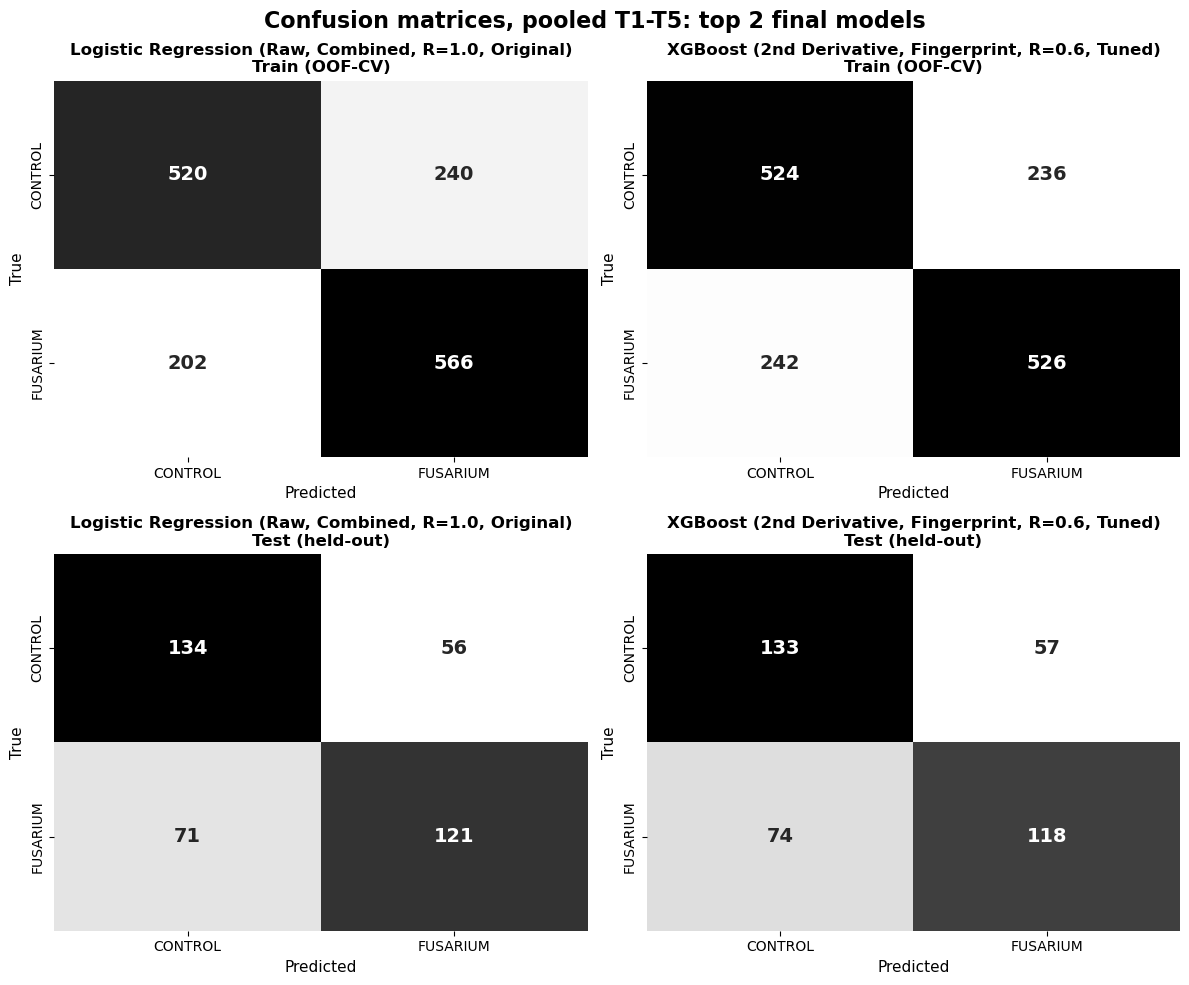

CPU times: total: 1.58 s
Wall time: 1.29 s


In [11]:
%%time
n_final = len(final_confusion_data)
fig, axes = plt.subplots(2, n_final, figsize=(6 * n_final, 10), squeeze=False)

for col, (label, cm_data) in enumerate(final_confusion_data.items()):
    for row_i, split in enumerate(['train', 'test']):
        ax = axes[row_i, col]
        sns.heatmap(cm_data[split], annot=True, fmt='d', cmap='Greys', cbar=False,
                    xticklabels=cm_data['classes'], yticklabels=cm_data['classes'], ax=ax,
                    annot_kws={'fontsize': 14, 'fontweight': 'bold'})
        split_label = 'Train (OOF-CV)' if split == 'train' else 'Test (held-out)'
        ax.set_title(f"{label}\n{split_label}", fontsize=12, fontweight='bold')
        ax.set_xlabel('Predicted', fontsize=11)
        ax.set_ylabel('True', fontsize=11)

plt.suptitle('Confusion matrices, pooled T1-T5: top 2 final models', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'Global_Top2_ConfusionMatrices_PooledT1T5.png'), dpi=150)
plt.show()

## Per-timepoint evaluation (T0–T7)

Candidates are tracked by `Candidate_Label` (model, spectrum type, region, R value, source), so two candidates with the same model name stay separate. Train-side metrics are out-of-fold CV predictions and not resubstitution, so they can be compared with the test metrics and any overfitting gap shows. Test MCC, accuracy and precision are reported for each timepoint.

The code below also draws three figures (MCC, accuracy, precision), each with the 2 models side by side and the pre-infection, asymptomatic and symptomatic phases marked.

In [12]:
%%time
per_timepoint_rows = []

for row in final_models_top2:
    model_name, R_value, label = row['Model'], row['R_value'], row['Candidate_Label']
    spectrum_type_name, region_name = row['Spectrum_Type'], row['Region']
    value_column = SPECTRUM_TYPES[spectrum_type_name]
    region_df = final_filtered_by_combo[(spectrum_type_name, region_name)]

    X_train_full, y_train_full, metadata_train = get_candidate_train_data(
        spectrum_type_name, region_name, R_value)

    cv_res = evaluate_model_on_cv_with_timepoint_breakdown(
        X_train_full, y_train_full, metadata_train, model_name,
        rebuild_estimator(model_name, spectrum_type_name, region_name, R_value, row['best_params']),
        n_folds=CV_FOLDS_TUNING)
    oof_df = cv_res['OOF_Predictions']

    fitted_bundle = fit_production_model(
        X_train_full, y_train_full, model_name,
        rebuild_estimator(model_name, spectrum_type_name, region_name, R_value, row['best_params']))
    le = fitted_bundle['label_encoder']

    filtered_R = region_df[region_df['R_value'] == R_value]

    for tp in ALL_TIMEPOINTS:
        tp_oof = oof_df[oof_df['timepoint'] == tp]
        if tp_oof['y_true'].nunique() > 1:
            train_tp = compute_classification_metrics(tp_oof['y_true'].values, tp_oof['y_pred'].values)
        else:
            train_tp = {'Accuracy': np.nan, 'Precision': np.nan, 'MCC': np.nan}

        test_tp_data = filtered_R[filtered_R['sample_name2'].isin(test_samples) &
                                  (filtered_R['timepoint'] == tp)]
        if len(test_tp_data) == 0:
            continue
        X_test_tp, metadata_test_tp = pivot_with_metadata(test_tp_data, value_column)

        y_test_tp_pred = predict_with_bundle(fitted_bundle, X_test_tp, model_name)
        test_tp = compute_classification_metrics(
            le.transform(metadata_test_tp['infection_status']), y_test_tp_pred)

        per_timepoint_rows.append({
            'Candidate_Label': label, 'Spectrum_Type': spectrum_type_name, 'Region': region_name,
            'Model': model_name, 'R_value': R_value, 'Timepoint': tp,
            'Display_Timepoint': convert_timepoint(tp),
            'Train_MCC_OOF': train_tp['MCC'],
            'Train_Accuracy_OOF': train_tp['Accuracy'],
            'Train_Precision_OOF': train_tp['Precision'],
            'Test_MCC': test_tp['MCC'],
            'Test_Accuracy': test_tp['Accuracy'],
            'Test_Precision': test_tp['Precision'],
        })

per_timepoint_final_df = pd.DataFrame(per_timepoint_rows)
per_timepoint_final_df.to_csv(
    os.path.join(OUTPUT_DIR, 'Global_Final_Top2_PerTimepoint_Metrics.csv'), index=False)

for label, sub in per_timepoint_final_df.groupby('Candidate_Label', sort=False):
    print(f"\n{label}")
    print(sub.drop(columns=['Candidate_Label', 'Spectrum_Type', 'Region', 'Model', 'R_value'])
          .to_string(index=False))


Logistic Regression (Raw, Combined, R=1.0, Original)
Timepoint Display_Timepoint  Train_MCC_OOF  Train_Accuracy_OOF  Train_Precision_OOF  Test_MCC  Test_Accuracy  Test_Precision
       T0              0dpi            NaN                 NaN                  NaN  0.094157       0.547368        0.547059
       T1              3dpi       0.392863            0.696078             0.684848  0.131991       0.565789        0.571429
       T2              7dpi       0.382109            0.690789             0.701389  0.401498       0.692308        0.766667
       T3             10dpi       0.570146            0.784314             0.765060  0.451292       0.723684        0.757576
       T4             14dpi       0.373052            0.686275             0.676829  0.368932       0.684211        0.694444
       T5             17dpi       0.393217            0.696078             0.682635  0.345106       0.671053        0.651163
       T6             21dpi            NaN                 NaN         

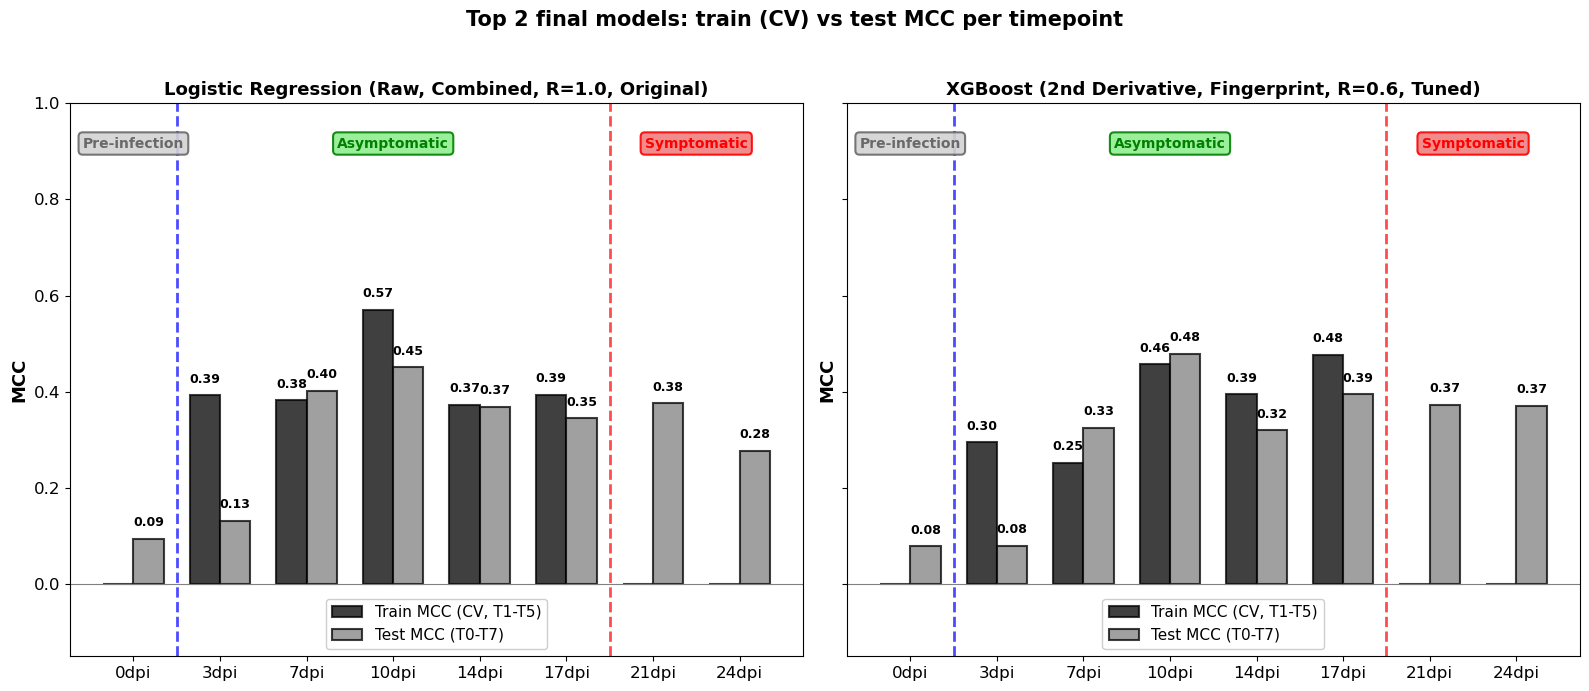

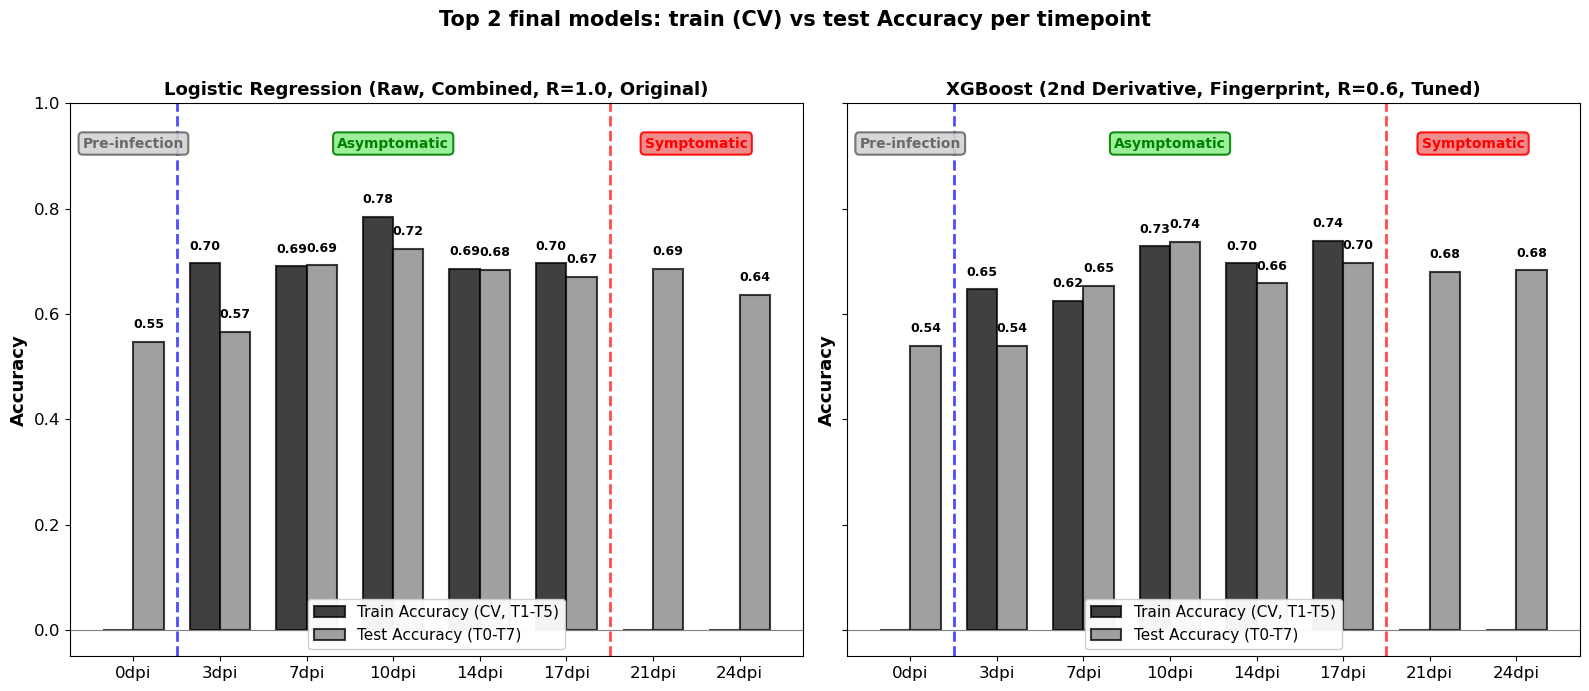

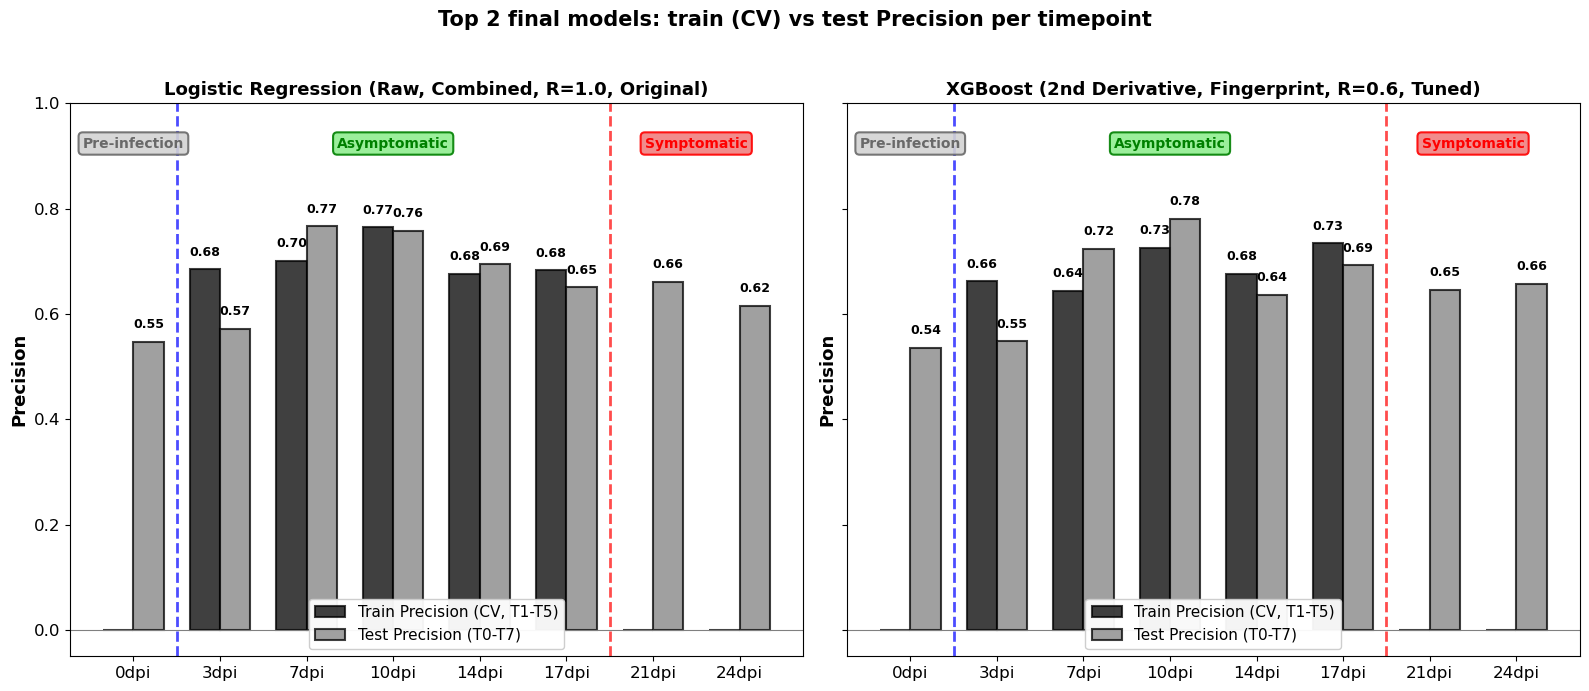

CPU times: total: 3.67 s
Wall time: 3.48 s


In [13]:
%%time
FONT_SIZES = {'title': 15, 'subtitle': 13, 'axis_label': 13, 'axis_ticks': 12,
              'bar_values': 9, 'legend': 11, 'section_labels': 10}

candidate_labels_ordered = [row['Candidate_Label'] for row in final_models_top2]

PHASES = [
    ('Pre-infection', 'T0', 'T0', 'dimgrey', 'lightgrey'),
    ('Asymptomatic', 'T1', 'T5', 'green', 'lightgreen'),
    ('Symptomatic', 'T6', 'T7', 'red', 'lightcoral'),
]


def add_phase_annotations(ax, sub):
    position = {tp: i for i, tp in enumerate(sub['Timepoint'])}
    y_low, y_top = ax.get_ylim()
    label_y = y_top - 0.06 * (y_top - y_low)

    for label, first, last, text_color, box_color in PHASES:
        if first in position and last in position:
            ax.text((position[first] + position[last]) / 2, label_y, label, ha='center', va='top',
                    fontsize=FONT_SIZES['section_labels'], fontweight='bold', color=text_color,
                    bbox=dict(boxstyle='round,pad=0.3', facecolor=box_color,
                              alpha=0.9, edgecolor=text_color, linewidth=1.5))
    if 'T5' in position and 'T6' in position:
        ax.axvline(x=(position['T5'] + position['T6']) / 2, color='red', linestyle='--', alpha=0.7, linewidth=2)
    if 'T0' in position and 'T1' in position:
        ax.axvline(x=(position['T0'] + position['T1']) / 2, color='blue', linestyle='--', alpha=0.7, linewidth=2)


def plot_metric_across_models(metric_key_train, metric_key_test, metric_display_name, fname_suffix):
    n_final = len(candidate_labels_ordered)
    fig, axes = plt.subplots(1, n_final, figsize=(8 * n_final, 7), sharey=True, squeeze=False)

    for ax, label in zip(axes[0], candidate_labels_ordered):
        sub = per_timepoint_final_df[per_timepoint_final_df['Candidate_Label'] == label].reset_index(drop=True)
        x = np.arange(len(sub))
        width = 0.35

        series = [
            (x - width / 2, sub[metric_key_train], f'Train {metric_display_name} (CV, T1-T5)', '#000000'),
            (x + width / 2, sub[metric_key_test], f'Test {metric_display_name} (T0-T7)', '#808080'),
        ]
        for positions, values, bar_label, color in series:
            bars = ax.bar(positions, values.fillna(0), width, label=bar_label,
                          color=color, alpha=0.75, edgecolor='black', linewidth=1.5)
            for bar, val in zip(bars, values):
                if not np.isnan(val):
                    ax.text(bar.get_x() + bar.get_width() / 2., bar.get_height() + 0.02, f'{val:.2f}',
                            ha='center', va='bottom', fontsize=FONT_SIZES['bar_values'], fontweight='bold')

        ax.set_xticks(x)
        ax.set_xticklabels(sub['Display_Timepoint'], fontsize=FONT_SIZES['axis_ticks'])
        ax.set_ylabel(metric_display_name, fontsize=FONT_SIZES['axis_label'], fontweight='bold')
        ax.set_title(label, fontsize=FONT_SIZES['subtitle'], fontweight='bold')
        ax.tick_params(axis='y', labelsize=FONT_SIZES['axis_ticks'])
        ax.axhline(0, color='grey', linewidth=0.8)
        ax.set_ylim(-0.15 if metric_display_name == 'MCC' else -0.05, 1.0)
        ax.legend(fontsize=FONT_SIZES['legend'], loc='lower center', framealpha=0.95)
        add_phase_annotations(ax, sub)

    fig.suptitle(f'Top 2 final models: train (CV) vs test {metric_display_name} per timepoint',
                 fontsize=FONT_SIZES['title'], fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.savefig(os.path.join(OUTPUT_DIR, f'Global_Top2_PerTimepoint_{fname_suffix}.png'), dpi=150)
    plt.show()


for metric_key_train, metric_key_test, display_name in [
        ('Train_MCC_OOF', 'Test_MCC', 'MCC'),
        ('Train_Accuracy_OOF', 'Test_Accuracy', 'Accuracy'),
        ('Train_Precision_OOF', 'Test_Precision', 'Precision')]:
    plot_metric_across_models(metric_key_train, metric_key_test, display_name, display_name)

## Wavenumber importance (SHAP)

The model with the higher pooled CV MCC (`final_models_top2[0]`) is used to find which wavenumbers drive the CONTROL vs FUSARIUM separation. Nothing is hardcoded, so the section follows whichever combination comes out on top.

SHAP values are computed on the production model, fitted once on the pooled T1–T5 training data. The explainer depends on the model family. `TreeExplainer` is used for Random Forest, Decision Tree, AdaBoost, XGBoost and LightGBM. `LinearExplainer` with `feature_perturbation='correlation_dependent'` is used for Logistic Regression, LDA and PLS-DA, because the default `interventional` mode gives unstable values on highly correlated spectral features. The slower `KernelExplainer` is used for the rest (SVM, k-NN, MLP, 1D CNN).

The tree and linear explainers see only the final estimator and not the whole pipeline. When the pipeline includes a `StandardScaler`, the inputs are standardised with that scaler first, so the explained function is the one the model was trained on. SHAP values are then in standardised units (log-odds for Logistic Regression). `KernelExplainer` wraps the whole pipeline and takes the original values. For linear models the cell prints the largest gap between the model score and the base value plus the summed SHAP values, which should be close to zero.

Wavenumbers are not ranked by overall |SHAP|, which mixes both classes. The samples are split by `infection_status` and the average signed SHAP value is computed within each class (`mean_shap_fusarium`, `mean_shap_control`). Their difference, `shap_separation`, shows how differently a wavenumber pushes the prediction for Fusarium and Control samples, and it is the ranking metric here because a wavenumber can have a large overall |SHAP| and push both classes the same way. A separate column, `direction`, says whether the raw spectral value at that wavenumber is on average higher in Fusarium or in Control samples. It is computed from the data and not from the SHAP sign, so the two can disagree.

The bar chart shows the top 20 wavenumbers in shades of grey according to the size of `shap_separation`. The heatmap shows its sign over time, red towards Fusarium and blue towards Control. Both mark `direction` with an arrow (↑ higher in Fusarium, ↓ lower in Fusarium).

`LabelEncoder` sorts labels alphabetically, so Control is 0 and Fusarium is 1, and a positive SHAP value pushes towards Fusarium.

In [14]:
%%time
best_row = final_models_top2[0]
BEST_LABEL = best_row['Candidate_Label']
model_name, R_value, best_params = best_row['Model'], best_row['R_value'], best_row['best_params']
spectrum_type_name, region_name = best_row['Spectrum_Type'], best_row['Region']
value_column = SPECTRUM_TYPES[spectrum_type_name]
region_df = final_filtered_by_combo[(spectrum_type_name, region_name)]
OUT_PREFIX = f'{spectrum_type_name.replace(" ", "")}_{region_name}_{model_name}_R{R_value}'

print(f"{BEST_LABEL}: CV MCC {best_row['CV_MCC_Pooled_T1T5']:.3f} ± {best_row['CV_MCC_Std_Pooled_T1T5']:.3f}")

X_train_full, y_train_full, metadata_train = get_candidate_train_data(spectrum_type_name, region_name, R_value)
fitted_bundle = fit_production_model(
    X_train_full, y_train_full, model_name,
    rebuild_estimator(model_name, spectrum_type_name, region_name, R_value, best_params))
fitted_model = (fitted_bundle['fitted'] if model_name == '1D CNN'
                else fitted_bundle['fitted'].named_steps['model'])
wavenumbers = X_train_full.columns.values

y_train_clean = y_train_full.astype(str).str.strip()
unique_labels = sorted(y_train_clean.unique())
assert len(unique_labels) == 2, f"Expected 2 classes, found {unique_labels}"
CONTROL_LABEL, FUSARIUM_LABEL = unique_labels
is_fusarium_train = (y_train_clean.values == FUSARIUM_LABEL)
print(f"Train: {is_fusarium_train.sum()} {FUSARIUM_LABEL}, {(~is_fusarium_train).sum()} {CONTROL_LABEL}")

TREE_MODELS = {'Random Forest', 'Decision Tree', 'AdaBoost', 'XGBoost', 'LightGBM'}
LINEAR_MODELS = {'Logistic Regression', 'LDA', 'PLS-DA'}
ARROWS = {f'higher_in_{FUSARIUM_LABEL}': '\u2191', f'higher_in_{CONTROL_LABEL}': '\u2193'}

fitted_scaler = (None if model_name == '1D CNN'
                 else getattr(fitted_bundle['fitted'], 'named_steps', {}).get('scaler'))
standardize_inputs = (model_name in (TREE_MODELS | LINEAR_MODELS)) and fitted_scaler is not None
EXPLAIN_SPACE_LABEL = 'standardized features' if standardize_inputs else 'original features'


def to_explain_space(X):
    if not standardize_inputs:
        return X
    return pd.DataFrame(fitted_scaler.transform(np.asarray(X, dtype=float)),
                        index=X.index, columns=X.columns)


def build_shap_explainer(model_name, fitted_model, X_background):
    if model_name in TREE_MODELS:
        return shap.TreeExplainer(fitted_model)
    if model_name in LINEAR_MODELS:
        try:
            return shap.LinearExplainer(fitted_model, X_background,
                                        feature_perturbation='correlation_dependent')
        except Exception:
            print("correlation_dependent failed, using the interventional mode")
            return shap.LinearExplainer(fitted_model, X_background)

    background = shap.sample(X_background, min(50, len(X_background)), random_state=SEED)
    if model_name == '1D CNN':
        def predict_fn(X):
            return fitted_model.predict(scale_for_cnn(fitted_bundle['scaler'], X)).flatten()
    else:
        pipeline = fitted_bundle['fitted']
        predict_fn = pipeline.predict_proba if hasattr(pipeline, 'predict_proba') else pipeline.predict
    return shap.KernelExplainer(predict_fn, background)

Logistic Regression (Raw, Combined, R=1.0, Original): CV MCC 0.423 ± 0.044
Train: 768 FUSARIUM, 760 CONTROL
CPU times: total: 2.5 s
Wall time: 1.37 s


Estimating transforms:   0%|          | 0/1000 [00:00<?, ?it/s]

Max SHAP reconstruction error: 8.49e-13
 wavenumber  shap_separation_fusarium_minus_control          direction
    3766.06                                0.012881  higher_in_CONTROL
    1315.75                                0.011087  higher_in_CONTROL
    1282.81                                0.010746  higher_in_CONTROL
    2843.59                                0.010601  higher_in_CONTROL
    1284.87                                0.010198  higher_in_CONTROL
    1278.69                                0.010007  higher_in_CONTROL
    1630.79                                0.009565 higher_in_FUSARIUM
    1280.75                                0.009409  higher_in_CONTROL
    2954.78                                0.009212  higher_in_CONTROL
    1628.73                                0.008960 higher_in_FUSARIUM
    1585.49                                0.008570  higher_in_CONTROL
    2952.72                                0.008511  higher_in_CONTROL
    3603.39                          

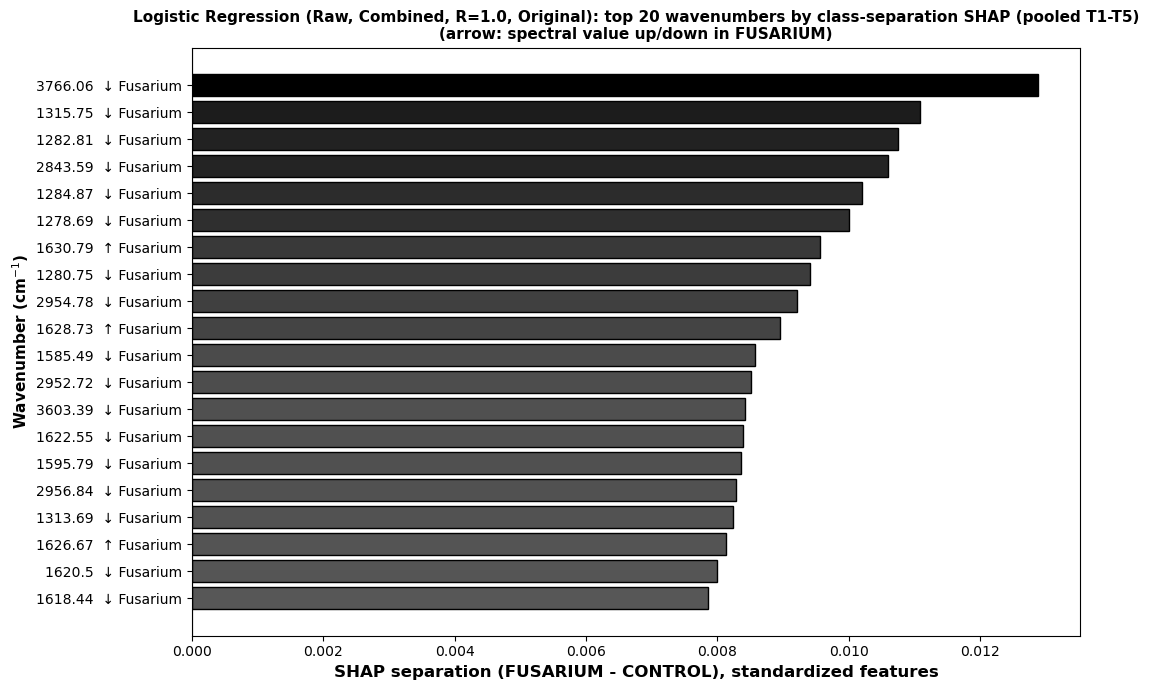

CPU times: total: 6h 22min 15s
Wall time: 1h 36min 36s


In [15]:
%%time
def get_shap_matrix(explainer_obj, X):
    sv = explainer_obj.shap_values(X)
    return sv[1] if isinstance(sv, list) else sv


X_explain_train = to_explain_space(X_train_full)
explainer = build_shap_explainer(model_name, fitted_model, X_explain_train)
shap_values_train = get_shap_matrix(explainer, X_explain_train)

if model_name in LINEAR_MODELS and hasattr(fitted_model, 'decision_function'):
    margin = fitted_model.decision_function(np.asarray(X_explain_train, dtype=float))
    rebuilt = np.ravel(explainer.expected_value)[0] + shap_values_train.sum(axis=1)
    print(f"Max SHAP reconstruction error: {np.max(np.abs(margin - rebuilt)):.3g}")

model_coefficients = (np.ravel(fitted_model.coef_) if hasattr(fitted_model, 'coef_')
                      else np.full(len(wavenumbers), np.nan))

mean_shap_fusarium = shap_values_train[is_fusarium_train].mean(axis=0)
mean_shap_control = shap_values_train[~is_fusarium_train].mean(axis=0)
shap_separation = mean_shap_fusarium - mean_shap_control

mean_value_fusarium = X_train_full.values[is_fusarium_train].mean(axis=0)
mean_value_control = X_train_full.values[~is_fusarium_train].mean(axis=0)
value_diff = mean_value_fusarium - mean_value_control

global_class_shap_df = pd.DataFrame({
    'wavenumber': wavenumbers,
    'shap_separation_fusarium_minus_control': shap_separation,
    'mean_abs_shap_overall': np.abs(shap_values_train).mean(axis=0),
    'model_coefficient': model_coefficients,
    'mean_value_fusarium': mean_value_fusarium,
    'mean_value_control': mean_value_control,
    'direction': np.where(value_diff > 0, f'higher_in_{FUSARIUM_LABEL}', f'higher_in_{CONTROL_LABEL}'),
}).sort_values('shap_separation_fusarium_minus_control', key=np.abs, ascending=False).reset_index(drop=True)

global_class_shap_df.to_csv(
    os.path.join(OUTPUT_DIR, f'{OUT_PREFIX}_SHAP_ClassSeparation_Pooled.csv'), index=False)

top_n = 20
print(global_class_shap_df.head(top_n)[['wavenumber', 'shap_separation_fusarium_minus_control', 'direction']]
      .to_string(index=False))

top_df = global_class_shap_df.head(top_n).iloc[::-1]
separation = top_df['shap_separation_fusarium_minus_control']
colors = [plt.cm.Greys(0.3 + 0.7 * val) for val in separation.abs() / separation.abs().max()]
ytick_labels = [f"{wn}  {ARROWS[d]} Fusarium" for wn, d in zip(top_df['wavenumber'].astype(str), top_df['direction'])]

fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(ytick_labels, separation, color=colors, edgecolor='black')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel(f'SHAP separation ({FUSARIUM_LABEL} - {CONTROL_LABEL}), {EXPLAIN_SPACE_LABEL}',
              fontsize=12, fontweight='bold')
ax.set_ylabel('Wavenumber (cm$^{-1}$)', fontsize=11, fontweight='bold')
ax.set_title(f'{BEST_LABEL}: top {top_n} wavenumbers by class-separation SHAP (pooled T1-T5)\n'
             f'(arrow: spectral value up/down in {FUSARIUM_LABEL})', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'{OUT_PREFIX}_SHAP_ClassSeparation_Top{top_n}_Grayscale.png'), dpi=150)
plt.show()

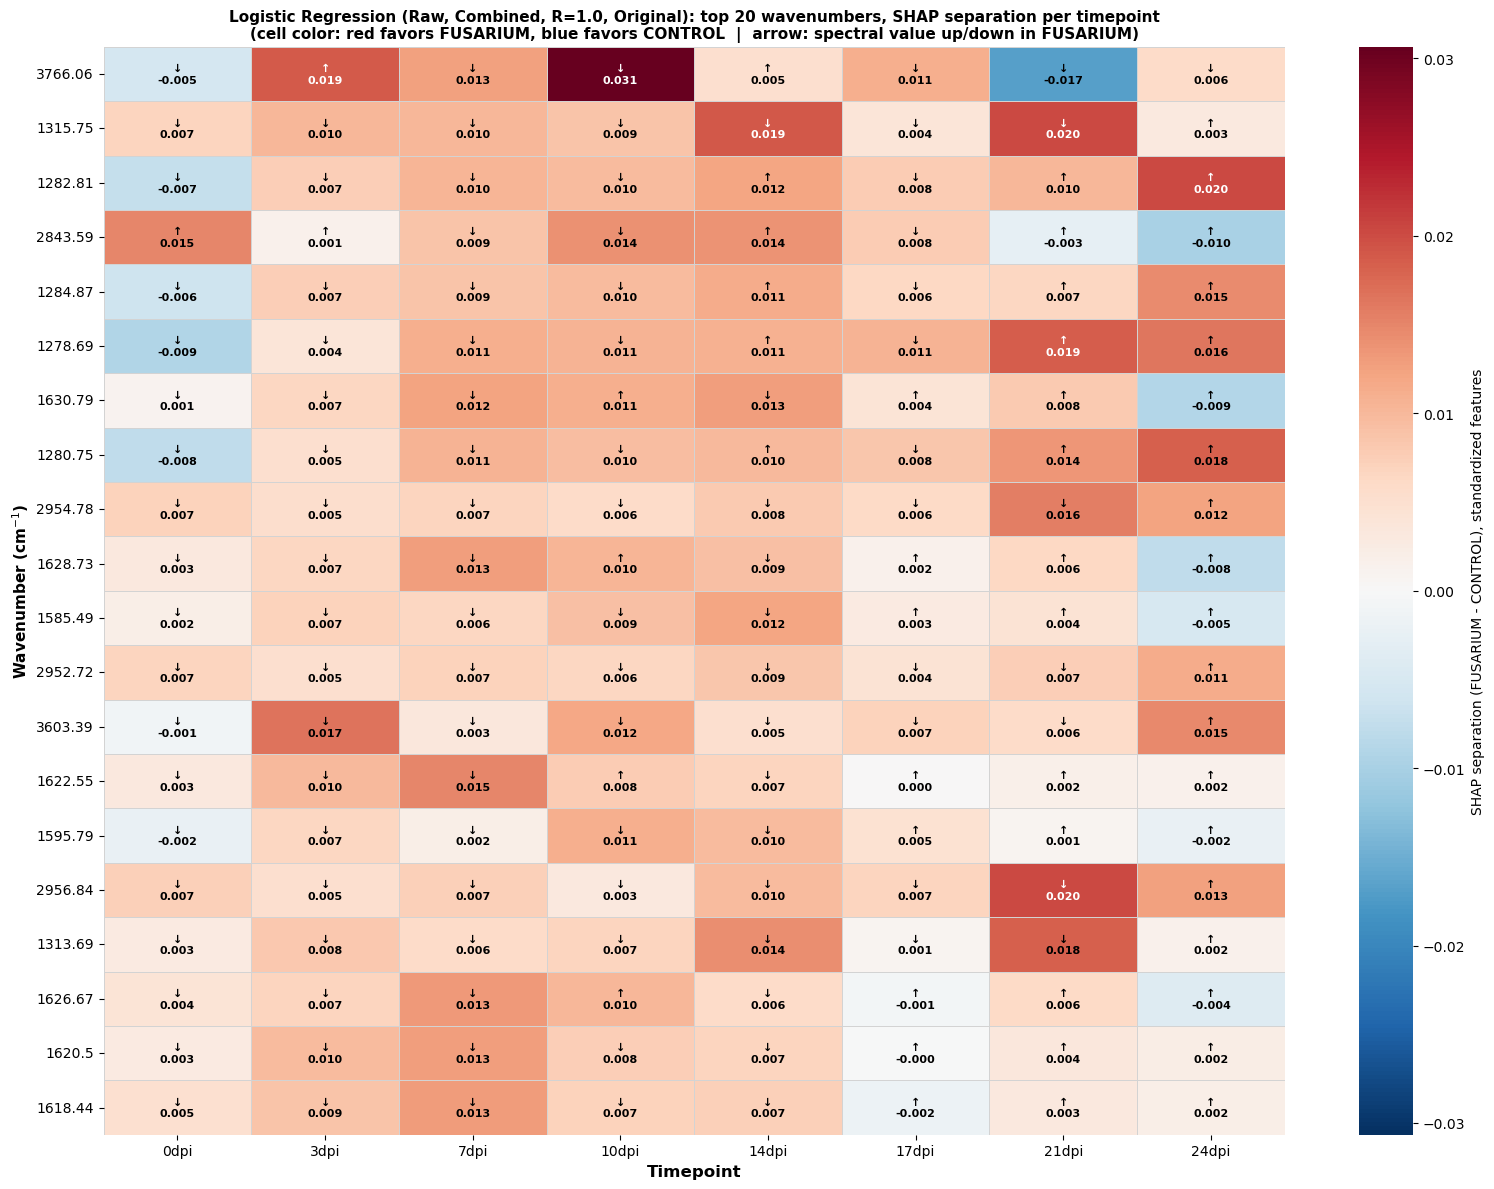


0dpi
 wavenumber  shap_separation_fusarium_minus_control          direction
    1797.58                               -0.018006  higher_in_CONTROL
    3595.15                                0.015012  higher_in_CONTROL
    2843.59                                0.014872 higher_in_FUSARIUM
    3636.33                                0.010601  higher_in_CONTROL
    1323.99                               -0.010171  higher_in_CONTROL

3dpi
 wavenumber  shap_separation_fusarium_minus_control          direction
    3766.06                                0.018782 higher_in_FUSARIUM
    3603.39                                0.016543  higher_in_CONTROL
    1793.46                                0.015317  higher_in_CONTROL
    1791.40                                0.013885  higher_in_CONTROL
    3745.46                                0.010450 higher_in_FUSARIUM

7dpi
 wavenumber  shap_separation_fusarium_minus_control          direction
    3636.33                                0.017952  higher

In [16]:
%%time
filtered_R = region_df[region_df['R_value'] == R_value]
top_pooled_wavenumbers = global_class_shap_df.head(20)['wavenumber'].tolist()

per_tp_rows = []
for tp in ALL_TIMEPOINTS:
    tp_data = filtered_R[filtered_R['timepoint'] == tp]
    if len(tp_data) == 0:
        continue
    X_tp = tp_data.pivot(index='sample_name', columns='wavenumber', values=value_column)
    X_tp = X_tp.reindex(columns=wavenumbers)
    if X_tp.isna().any().any():
        X_tp = X_tp.fillna(X_train_full.mean())

    y_tp = (tp_data.drop_duplicates(subset='sample_name').set_index('sample_name')
            .loc[X_tp.index, 'infection_status'].astype(str).str.strip())
    is_fus_tp = (y_tp.values == FUSARIUM_LABEL)
    if is_fus_tp.sum() == 0 or (~is_fus_tp).sum() == 0:
        print(f"Skipping {tp}: only one class present")
        continue

    shap_tp = get_shap_matrix(explainer, to_explain_space(X_tp))
    sep_tp = shap_tp[is_fus_tp].mean(axis=0) - shap_tp[~is_fus_tp].mean(axis=0)
    value_diff_tp = X_tp.values[is_fus_tp].mean(axis=0) - X_tp.values[~is_fus_tp].mean(axis=0)

    for wn, s, vd in zip(wavenumbers, sep_tp, value_diff_tp):
        per_tp_rows.append({
            'Timepoint': tp,
            'Display_Timepoint': convert_timepoint(tp),
            'wavenumber': wn,
            'shap_separation_fusarium_minus_control': s,
            'direction': f'higher_in_{FUSARIUM_LABEL}' if vd > 0 else f'higher_in_{CONTROL_LABEL}',
            'n_fusarium': int(is_fus_tp.sum()),
            'n_control': int((~is_fus_tp).sum()),
        })

per_tp_class_shap_df = pd.DataFrame(
    per_tp_rows,
    columns=['Timepoint', 'Display_Timepoint', 'wavenumber', 'shap_separation_fusarium_minus_control',
             'direction', 'n_fusarium', 'n_control'])
per_tp_class_shap_df.to_csv(
    os.path.join(OUTPUT_DIR, f'{OUT_PREFIX}_SHAP_ClassSeparation_PerTimepoint.csv'), index=False)

if len(per_tp_class_shap_df) > 0:
    heat_df = per_tp_class_shap_df[per_tp_class_shap_df['wavenumber'].isin(top_pooled_wavenumbers)]
    tp_order = [convert_timepoint(tp) for tp in ALL_TIMEPOINTS
                if convert_timepoint(tp) in set(heat_df['Display_Timepoint'])]
    heat_pivot = (heat_df.pivot(index='wavenumber', columns='Display_Timepoint',
                                values='shap_separation_fusarium_minus_control')
                  .reindex(index=top_pooled_wavenumbers, columns=tp_order))
    direction_pivot = (heat_df.pivot(index='wavenumber', columns='Display_Timepoint', values='direction')
                       .reindex(index=top_pooled_wavenumbers, columns=tp_order))

    vmax = np.nanmax(np.abs(heat_pivot.values))
    fig, ax = plt.subplots(figsize=(16, 12))
    sns.heatmap(heat_pivot, cmap='RdBu_r', center=0, vmin=-vmax, vmax=vmax, annot=False,
                linewidths=0.5, linecolor='lightgrey',
                yticklabels=[str(wn) for wn in heat_pivot.index],
                cbar_kws={'label': f'SHAP separation ({FUSARIUM_LABEL} - {CONTROL_LABEL}), {EXPLAIN_SPACE_LABEL}'},
                ax=ax)

    for i, wn in enumerate(heat_pivot.index):
        for j, tp in enumerate(heat_pivot.columns):
            shap_val = heat_pivot.loc[wn, tp]
            direction = direction_pivot.loc[wn, tp]
            if not pd.isna(shap_val) and not pd.isna(direction):
                ax.text(j + 0.5, i + 0.5, f"{ARROWS.get(direction, chr(0x2193))}\n{shap_val:.3f}",
                        ha='center', va='center',
                        color='white' if abs(shap_val) > vmax * 0.6 else 'black',
                        fontsize=8, fontweight='bold')

    ax.set_title(f'{BEST_LABEL}: top 20 wavenumbers, SHAP separation per timepoint\n'
                 f'(cell color: red favors {FUSARIUM_LABEL}, blue favors {CONTROL_LABEL}  |  '
                 f'arrow: spectral value up/down in {FUSARIUM_LABEL})',
                 fontsize=11, fontweight='bold')
    ax.set_xlabel('Timepoint', fontsize=12, fontweight='bold')
    ax.set_ylabel('Wavenumber (cm$^{-1}$)', fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f'{OUT_PREFIX}_SHAP_ClassSeparation_PerTimepoint_Heatmap_Top20_with_arrows.png'),
                dpi=150)
    plt.show()

    for tp in ALL_TIMEPOINTS:
        sub = per_tp_class_shap_df[per_tp_class_shap_df['Timepoint'] == tp]
        if len(sub) == 0:
            continue
        top5 = sub.reindex(sub['shap_separation_fusarium_minus_control'].abs()
                           .sort_values(ascending=False).index).head(5)
        print(f"\n{convert_timepoint(tp)}")
        print(top5[['wavenumber', 'shap_separation_fusarium_minus_control', 'direction']].to_string(index=False))